# Notebook 6 – Multivariate Analysis
**File:** `06_Multivariate_Analysis.ipynb`

## Objective
Explore relationships among several variables, identify strong/weak/negative correlations, potential multicollinearity, and feature interactions. Examples use Telco Customer Churn.

## Setup and load data

This notebook uses the IBM Telco Customer Churn dataset. Put `WA_Fn-UseC_-Telco-Customer-Churn.csv` beside this notebook, or change `DATA_PATH` below.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")

DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
DATA_PATH = Path( r"C:\Users\ramki\sprint_4\dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV not found at {DATA_PATH.resolve()}. Update DATA_PATH.")
df = pd.read_csv(DATA_PATH)
if "TotalCharges" in df:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Shape:", df.shape)
display(df.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Prepare numerical features
Correlation and pair plots use numerical inputs. Avoid assigning arbitrary integer codes to nominal categories and then interpreting their correlations as meaningful.

In [2]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [c for c in numeric_cols if c.lower() not in {"customerid", "customer_id", "id"}]
if not numeric_cols:
    raise ValueError("No numeric columns detected.")
numeric_df = df[numeric_cols].replace([np.inf, -np.inf], np.nan)
print("Numerical features:", numeric_cols)
display(numeric_df.describe().T.round(3))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162,0.369,0.00,0.00,0.000,0.000,1.00
tenure,7043.0,32.371,24.559,0.00,9.00,29.000,55.000,72.00
MonthlyCharges,7043.0,64.762,30.090,18.25,35.50,70.350,89.850,118.75
TotalCharges,7032.0,2283.300,2266.771,18.80,401.45,1397.475,3794.738,8684.80


## 2. Correlation matrix
The correlation matrix reports pairwise linear correlations. Positive values indicate variables tend to increase together; negative values indicate opposite movement; values near zero indicate weak linear association.

**AI/ML relevance:** Highly correlated predictors may be redundant and can complicate interpretation of some models.

In [3]:
corr = numeric_df.corr(method="pearson", min_periods=2)
display(corr.round(3))

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000,0.017,0.220,0.102
tenure,0.017,1.000,0.248,0.826
MonthlyCharges,0.220,0.248,1.000,0.651
TotalCharges,0.102,0.826,0.651,1.000


## 3. Heatmap and high-correlation pairs
A heatmap makes strong positive and negative relationships easier to see. Absolute correlation around 0.8 or 0.9 is sometimes used as a screening threshold for potential multicollinearity, but context matters.

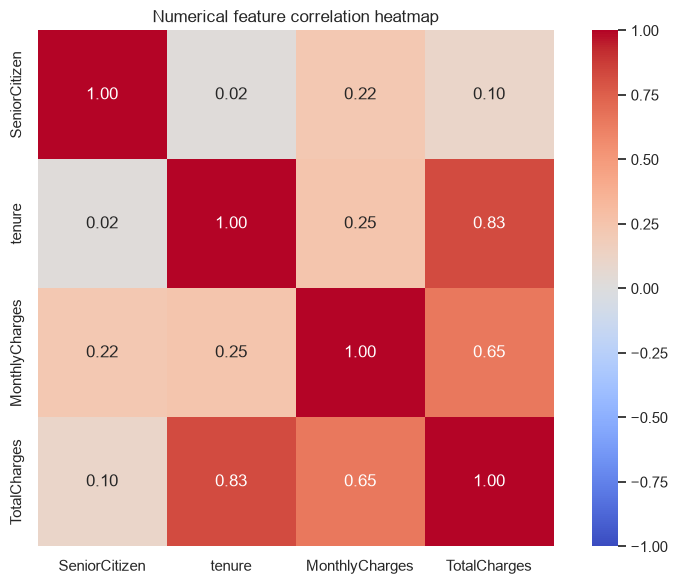

,feature_1,feature_2,correlation
0,tenure,TotalCharges,0.82588


In [4]:
plt.figure(figsize=(max(8, len(corr.columns)*.8), max(6, len(corr.columns)*.65)))
sns.heatmap(corr, annot=len(corr.columns) <= 12, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True)
plt.title("Numerical feature correlation heatmap"); plt.tight_layout(); plt.show()

threshold = .80
pairs = []
for i, c1 in enumerate(corr.columns):
    for c2 in corr.columns[i+1:]:
        v = corr.loc[c1, c2]
        if pd.notna(v) and abs(v) >= threshold:
            pairs.append((c1, c2, v))
if pairs:
    display(pd.DataFrame(pairs, columns=["feature_1", "feature_2", "correlation"])
            .sort_values("correlation", key=lambda s: s.abs(), ascending=False))
else:
    print(f"No pairs with absolute correlation >= {threshold}.")

### Output explanation
- Strong positive: close to +1.
- Strong negative: close to -1.
- Weak linear relationship: close to 0.
- Potential multicollinearity: high absolute correlation between predictors.

This is a screening step, not a definitive multicollinearity test. Correlation with a target is not proof of usefulness, and target leakage must be ruled out.

## 4. Pair plot
Pair plots show pairwise scatter plots and single-feature distributions. Limit the number of features and sample rows so the plot remains readable.

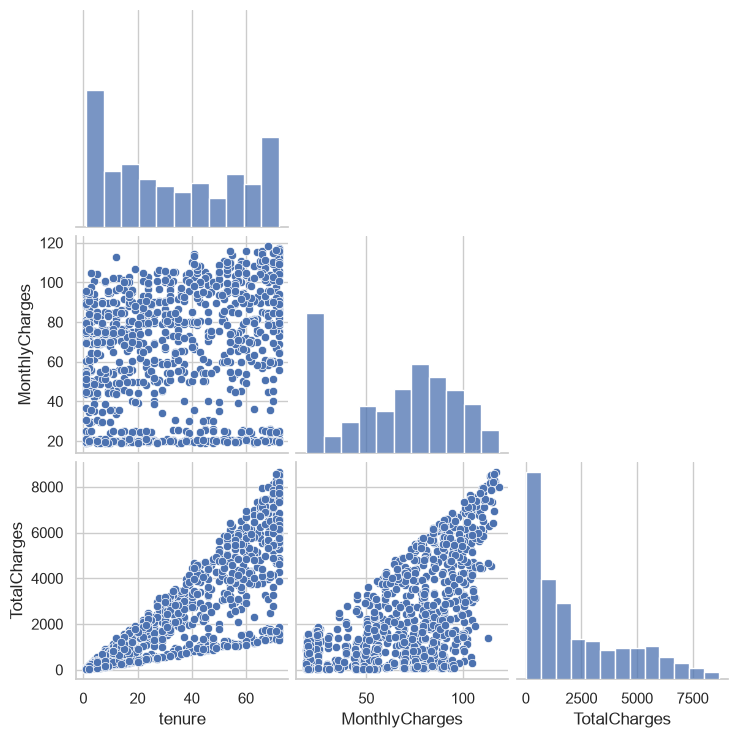

In [5]:
pair_cols = [c for c in ["tenure", "MonthlyCharges", "TotalCharges"] if c in numeric_df.columns]
if len(pair_cols) < 2:
    pair_cols = numeric_cols[:min(4, len(numeric_cols))]
if len(pair_cols) >= 2:
    p = numeric_df[pair_cols].dropna()
    if len(p) > 1000: p = p.sample(1000, random_state=42)
    sns.pairplot(p, diag_kind="hist", corner=True)
    plt.show()
else:
    print("At least two numeric columns are needed.")

### Output explanation
Look for linear/nonlinear patterns, clusters, changing spread, and extreme values. Diagonal plots show individual distributions. Confirm important patterns using statistics and domain knowledge.

## 5. Multiple feature relationships with the target
When `Churn` is available, compare several numerical features across target classes. This helps generate hypotheses about which features may differ by class.

In [6]:
features = [c for c in ["tenure", "MonthlyCharges", "TotalCharges"] if c in df.columns]
if "Churn" in df.columns and features:
    display(df.groupby("Churn")[features].agg(["count", "mean", "median", "std"]).round(3))
else:
    print("Target or example features unavailable; select columns manually.")

tenure                        MonthlyCharges                          \
       count    mean median     std          count    mean  median     std   
Churn                                                                        
No      5174  37.570   38.0  24.114           5174  61.265  64.425  31.093   
Yes     1869  17.979   10.0  19.531           1869  74.441  79.650  24.666   

      TotalCharges                               
             count      mean   median       std  
Churn                                            
No            5163  2555.344  1683.60  2329.457  
Yes           1869  1531.796   703.55  1890.823

## 6. Feature interactions
An interaction is possible when the relationship between one feature and an outcome changes depending on another feature. Coloring a scatter plot by a third variable is an exploratory check.

**Example:** `tenure` vs `MonthlyCharges`, colored by `Contract`.

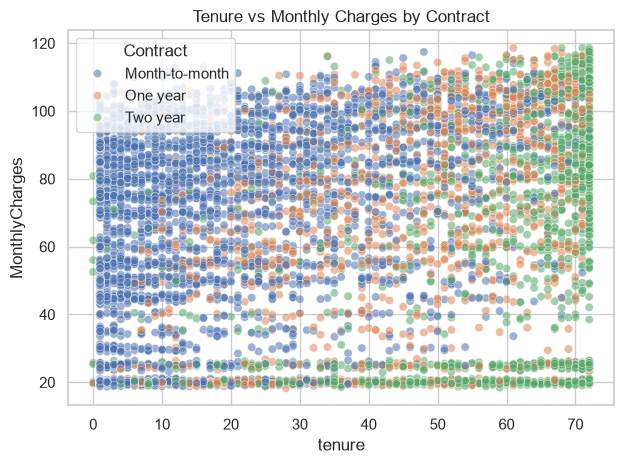

In [7]:
required = {"tenure", "MonthlyCharges", "Contract"}
if required.issubset(df.columns):
    p = df[["tenure", "MonthlyCharges", "Contract"]].copy()
    p["tenure"] = pd.to_numeric(p["tenure"], errors="coerce")
    p["MonthlyCharges"] = pd.to_numeric(p["MonthlyCharges"], errors="coerce")
    p = p.dropna()
    sns.scatterplot(data=p, x="tenure", y="MonthlyCharges", hue="Contract", alpha=.55)
    plt.title("Tenure vs Monthly Charges by Contract")
    plt.tight_layout(); plt.show()
else:
    print("Choose two numeric features and one categorical feature.")

### Output explanation
Look for different slopes, clusters, or spreads across groups. A visual pattern suggests an interaction to test; it does not confirm one. In ML, compare models with and without an interaction using appropriate validation.

## 7. Rank strongest positive, negative, and weakest pairs
This ranks unique pairs by correlation magnitude while retaining the sign.

In [8]:
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
ranked = upper.stack().rename("correlation").reset_index()
ranked.columns = ["feature_1", "feature_2", "correlation"]
ranked["absolute_correlation"] = ranked["correlation"].abs()
ranked = ranked.sort_values("absolute_correlation", ascending=False)
print("Strongest absolute correlations:"); display(ranked.head(10).round(3))
print("Most negative correlations:"); display(ranked.sort_values("correlation").head(10).round(3))
print("Weakest absolute correlations:"); display(ranked.sort_values("absolute_correlation").head(10).round(3))

Strongest absolute correlations:


,feature_1,feature_2,correlation,absolute_correlation
7,tenure,TotalCharges,0.826,0.826
11,MonthlyCharges,TotalCharges,0.651,0.651
6,tenure,MonthlyCharges,0.248,0.248
2,SeniorCitizen,MonthlyCharges,0.220,0.220
3,SeniorCitizen,TotalCharges,0.102,0.102
1,SeniorCitizen,tenure,0.017,0.017
0,SeniorCitizen,SeniorCitizen,NaN,NaN
4,tenure,SeniorCitizen,NaN,NaN
5,tenure,tenure,NaN,NaN
8,MonthlyCharges,SeniorCitizen,NaN,NaN


Most negative correlations:


,feature_1,feature_2,correlation,absolute_correlation
1,SeniorCitizen,tenure,0.017,0.017
3,SeniorCitizen,TotalCharges,0.102,0.102
2,SeniorCitizen,MonthlyCharges,0.220,0.220
6,tenure,MonthlyCharges,0.248,0.248
11,MonthlyCharges,TotalCharges,0.651,0.651
7,tenure,TotalCharges,0.826,0.826
0,SeniorCitizen,SeniorCitizen,NaN,NaN
4,tenure,SeniorCitizen,NaN,NaN
5,tenure,tenure,NaN,NaN
8,MonthlyCharges,SeniorCitizen,NaN,NaN


Weakest absolute correlations:


,feature_1,feature_2,correlation,absolute_correlation
1,SeniorCitizen,tenure,0.017,0.017
3,SeniorCitizen,TotalCharges,0.102,0.102
2,SeniorCitizen,MonthlyCharges,0.220,0.220
6,tenure,MonthlyCharges,0.248,0.248
11,MonthlyCharges,TotalCharges,0.651,0.651
7,tenure,TotalCharges,0.826,0.826
0,SeniorCitizen,SeniorCitizen,NaN,NaN
4,tenure,SeniorCitizen,NaN,NaN
5,tenure,tenure,NaN,NaN
8,MonthlyCharges,SeniorCitizen,NaN,NaN


## Findings checklist and conclusion
For each finding, record the feature pair/group, strength and direction, whether a plot supports the pattern, potential redundancy, a possible interaction, leakage concerns, and the next validation step (domain review, VIF, statistical test, or model comparison).

High correlation is not automatically a reason to drop a feature. Model type and validation performance matter. Conclude with the strongest positive/negative patterns, weak relationships, potential multicollinearity, and interaction hypotheses. These are exploratory observations, not causal conclusions.